# Zomato delivery time · EDA and feature selection

Predict delivery duration in minutes using inputs available when an order is placed. This notebook replays the repository’s cleaner, checks the chronological split, and evaluates feature groups on later validation orders. Model plots use training records. The newest test orders are reserved for final model evaluation.

Use the backend Python environment as your kernel. Install `requirements-training.txt` and `ipykernel`, then run all cells from the repository. The raw CSV and the cleaned, routed, and prepared Parquet files are included. [Data audit](01_data_audit.ipynb) · [Dataset configuration](../configs/dataset.yaml)

In [1]:
%matplotlib inline

import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.tree import DecisionTreeRegressor

cwd = Path.cwd().resolve()
backend = next(
    candidate
    for parent in (cwd, *cwd.parents)
    for candidate in (parent, parent / "apps" / "backend")
    if (candidate / "ml" / "configs" / "dataset.yaml").is_file()
)
if str(backend) not in sys.path:
    sys.path.insert(0, str(backend))

from ml.manifest import load_dataset_config, resolve_dataset_paths
from ml.pipeline import build_training_pipeline
from ml.prepared_data import prepare_partitions
from ml.preprocessing import clean_dataset
from ml.train import TIMESTAMP_COLUMN, split_routed_orders
from ml.validation import read_raw_csv

config = load_dataset_config()
paths = resolve_dataset_paths()
schema = config["schema"]
quality = config["quality"]
serving = config["serving"]
target = schema["target_column"]
selected = serving["model_features"]

plt.rcParams.update({
    "figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": "#243347",
    "xtick.color": "#243347", "ytick.color": "#243347",
})
teal, slate, rust = "#147d82", "#344963", "#b94d25"

## Reproduce the cleaning

The cleaner trims strings, maps missing markers to null, standardizes categories, and corrects the spelling of Metropolitan. It removes exact duplicate records, rejects unusable targets, and flags conflicting IDs for inspection. It parses local order timestamps and derives the hour and weekday. Invalid numeric fields and suspect GPS distances become null. Long positive delivery times remain available for review. Imputation happens later, after the split.

In [2]:
manifest = json.loads(paths.dataset_manifest.read_text(encoding="utf-8"))
raw_path = paths.raw_csv
if not raw_path.is_file():
    raw_path = raw_path.with_name(manifest["source_file"])

raw = read_raw_csv(raw_path, schema["required_columns"])
reproduced, audit = clean_dataset(raw, schema, quality)
cleaned = pd.read_parquet(paths.processed_parquet)
routed = pd.read_parquet(paths.routed_parquet)

with paths.processed_parquet.open("rb") as handle:
    assert hashlib.file_digest(handle, "sha256").hexdigest() == manifest["parquet_sha256"]
pd.testing.assert_frame_equal(reproduced, cleaned)
pd.testing.assert_frame_equal(cleaned, routed[cleaned.columns])

duplicates = audit["duplicates"]
rejected_targets = sum(audit["target_rejections"].values())
assert len(raw) == len(cleaned) + duplicates["exact_rows_removed"] + rejected_targets
display(pd.Series({
    "Raw orders": len(raw),
    "Cleaned orders": len(cleaned),
    "Exact duplicates removed": duplicates["exact_rows_removed"],
    "Conflicting order IDs": duplicates["conflicting_order_ids"],
    "Unusable targets removed": rejected_targets,
    "Restaurant endpoints at (0, 0)": audit["distance"]["coordinate_pair_issues"]["restaurant"]["zero_pair"],
    "Implausible straight-line distances": audit["distance"]["implausible_distances"],
    "Missing cleaned timestamps": audit["timestamps"]["null_timestamp"],
    "Ratings outside the 1–5 range": audit["numeric_features_quality"]["Delivery_person_Ratings"]["out_of_range"],
    "Deliveries above the review threshold": audit["target_review"]["long_deliveries"],
}, name="Orders").to_frame())

,Orders
Raw orders,45584
Cleaned orders,45584
Exact duplicates removed,0
Conflicting order IDs,0
Unusable targets removed,0
"Restaurant endpoints at (0, 0)",3640
Implausible straight-line distances,431
Missing cleaned timestamps,1731
Ratings outside the 1–5 range,53
Deliveries above the review threshold,0


## Verify the chronological split

The model requires a road distance within the serving bounds and a usable timestamp. The splitter orders records by time, puts cutoffs near 70% and 85%, and keeps equal timestamps together. The pipeline also checks for order IDs that appear in more than one partition. Rows with missing road distance are counted before the timestamp check.

In [3]:
routed_split = split_routed_orders(routed, target, serving["blocked_road_distance_km"])
split = routed_split.split
train, validation, test = split.train, split.validation, split.test
partitions = (train, validation, test)
assert len(routed) == (
    sum(map(len, partitions))
    + routed_split.missing_road_distance
    + routed_split.outside_road_distance_limits
    + split.missing_timestamps
    + split.invalid_timestamps
)
assert train[TIMESTAMP_COLUMN].max() < validation[TIMESTAMP_COLUMN].min()
assert validation[TIMESTAMP_COLUMN].max() < test[TIMESTAMP_COLUMN].min()
assert pd.Index(np.concatenate([orders.index.to_numpy() for orders in partitions])).is_unique

display(pd.Series({
    "Missing road distance": routed_split.missing_road_distance,
    "Road distance outside serving bounds": routed_split.outside_road_distance_limits,
    "Missing timestamp after route screening": split.missing_timestamps,
    "Invalid timestamp after route screening": split.invalid_timestamps,
}, name="Excluded orders").to_frame())
display(split.summary())

,Excluded orders
Missing road distance,7884
Road distance outside serving bounds,86
Missing timestamp after route screening,1198
Invalid timestamp after route screening,0


,Rows,Share (%),First order,Last order
Training,25489,69.99,2022-02-11 08:10:00,2022-03-25 19:30:00
Validation,5464,15.00,2022-03-25 19:35:00,2022-03-31 21:50:00
Test,5463,15.00,2022-03-31 21:55:00,2022-04-07 00:00:00


## Distributions and outliers

The 1.5 × IQR rule flags observations for review. The plots retain plausible tails because long trips and slow deliveries are part of the prediction problem. Route eligibility uses the app’s configured limits. See the cleaning replay above for GPS quality rules.

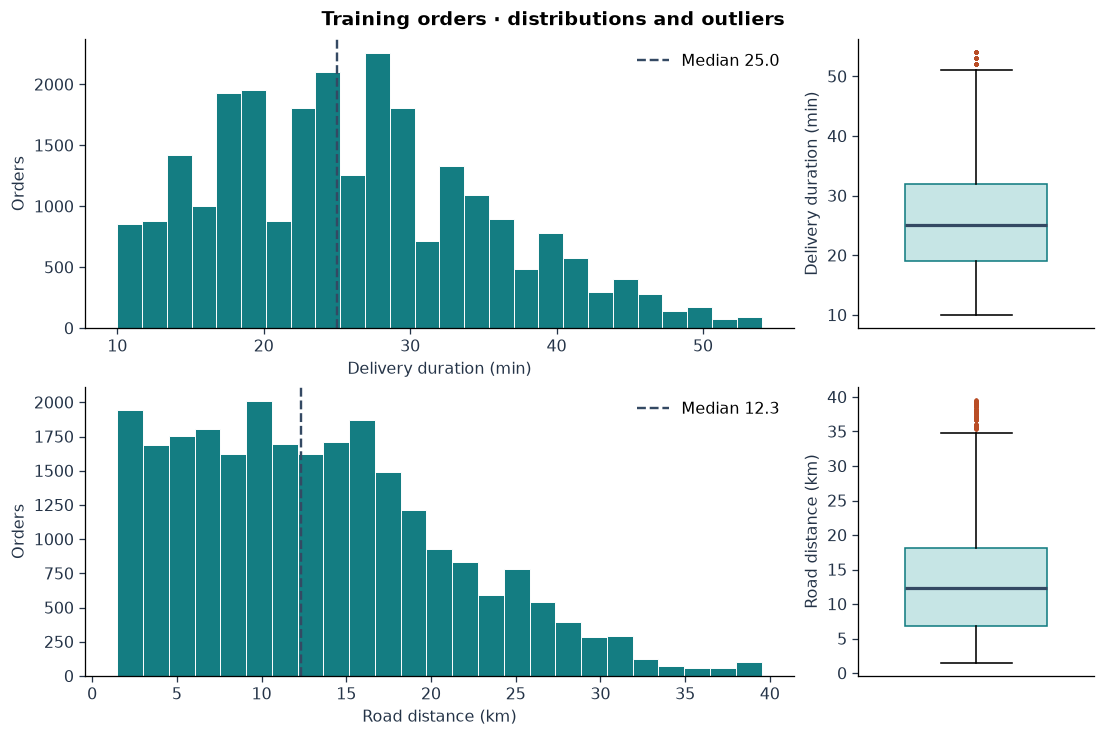

,Minimum,Median,Maximum,IQR lower fence,IQR upper fence,Outside fences
Measure,,,,,,
Delivery duration (min),10.00,25.00,54.00,-0.50,51.5,129
Road distance (km),1.49,12.31,39.51,-9.97,35.0,222


In [4]:
distributions = {
    target: ("Delivery duration (min)", 26),
    "road_distance_km": ("Road distance (km)", 25),
}
fig, axes = plt.subplots(2, 2, figsize=(9.5, 6.3), width_ratios=[3, 1], layout="constrained")
outlier_rows = []
for column, (label, bins), hist, box in zip(
    distributions, distributions.values(), axes[:, 0], axes[:, 1]
):
    values = train[column].dropna().to_numpy(dtype=float)
    q1, median, q3 = np.quantile(values, [0.25, 0.5, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "Measure": label, "Minimum": values.min(), "Median": median, "Maximum": values.max(),
        "IQR lower fence": low, "IQR upper fence": high,
        "Outside fences": int(((values < low) | (values > high)).sum()),
    })
    hist.hist(values, bins=bins, color=teal, edgecolor="white", linewidth=0.6)
    hist.axvline(median, color=slate, ls="--", label=f"Median {median:.1f}")
    hist.set(xlabel=label, ylabel="Orders")
    hist.legend(frameon=False)
    box.boxplot([values], widths=0.6, patch_artist=True,
                boxprops={"facecolor": "#c6e5e5", "edgecolor": teal},
                medianprops={"color": slate, "linewidth": 2},
                flierprops={"marker": ".", "markersize": 3, "markeredgecolor": rust})
    box.set(ylim=hist.get_xlim(), ylabel=label, xticks=[])
fig.suptitle("Training orders · distributions and outliers", fontweight="bold")
plt.show()
display(pd.DataFrame(outlier_rows).set_index("Measure").round(2))

## Correlations and order-time patterns

Pearson correlation summarizes linear relationships. Ratings and batching can correlate with delivery time, but their values depend on rider assignment or have unverified availability at order placement. Road distance is also closely correlated with straight-line distance and estimated drive time.

The category plots show sample counts alongside the medians and quartiles. Missing festival labels occur on 128 training orders and cluster at unusually short delivery times. The app always supplies a festival status and city type. The validation comparison also checks orders with both fields present. The Semi-Urban category has only 82 training orders.

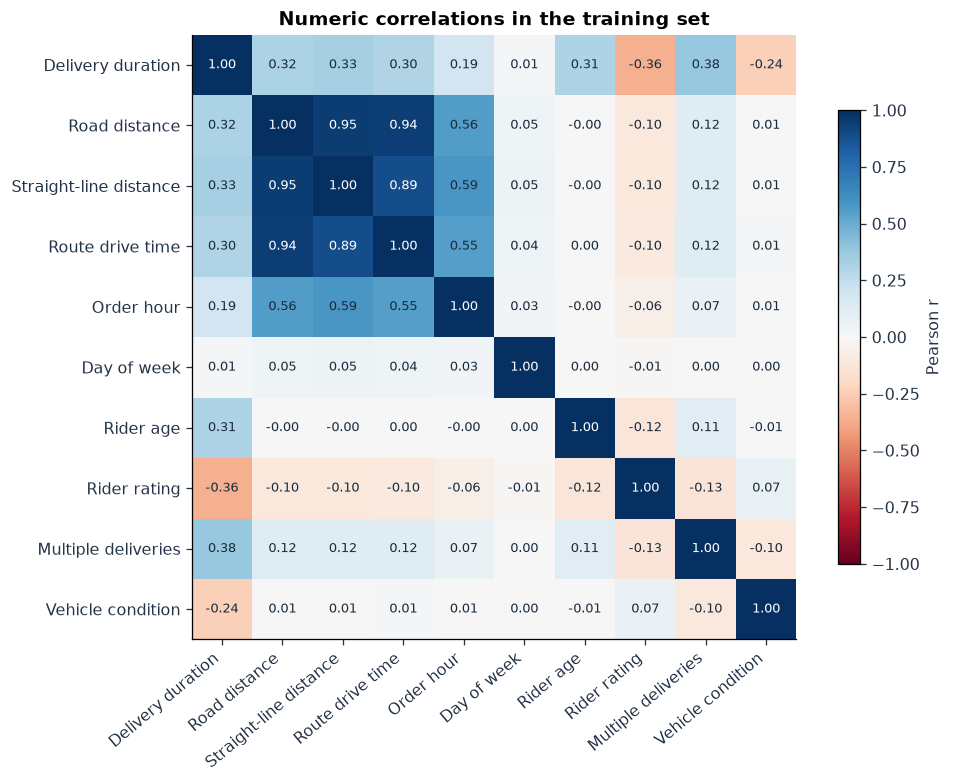

In [5]:
numeric_labels = {
    target: "Delivery duration", "road_distance_km": "Road distance", "distance_km": "Straight-line distance",
    "route_duration_minutes": "Route drive time", "order_hour": "Order hour",
    "order_day_of_week": "Day of week", "Delivery_person_Age": "Rider age",
    "Delivery_person_Ratings": "Rider rating", "multiple_deliveries": "Multiple deliveries",
    "Vehicle_condition": "Vehicle condition",
}
corr = train[list(numeric_labels)].rename(columns=numeric_labels).corr()
fig, ax = plt.subplots(figsize=(8.8, 6.7), layout="constrained")
matrix = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for row, line in enumerate(corr.to_numpy()):
    for col, value in enumerate(line):
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.65 else "#192b3c")
fig.colorbar(matrix, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title("Numeric correlations in the training set", fontweight="bold")
plt.show()

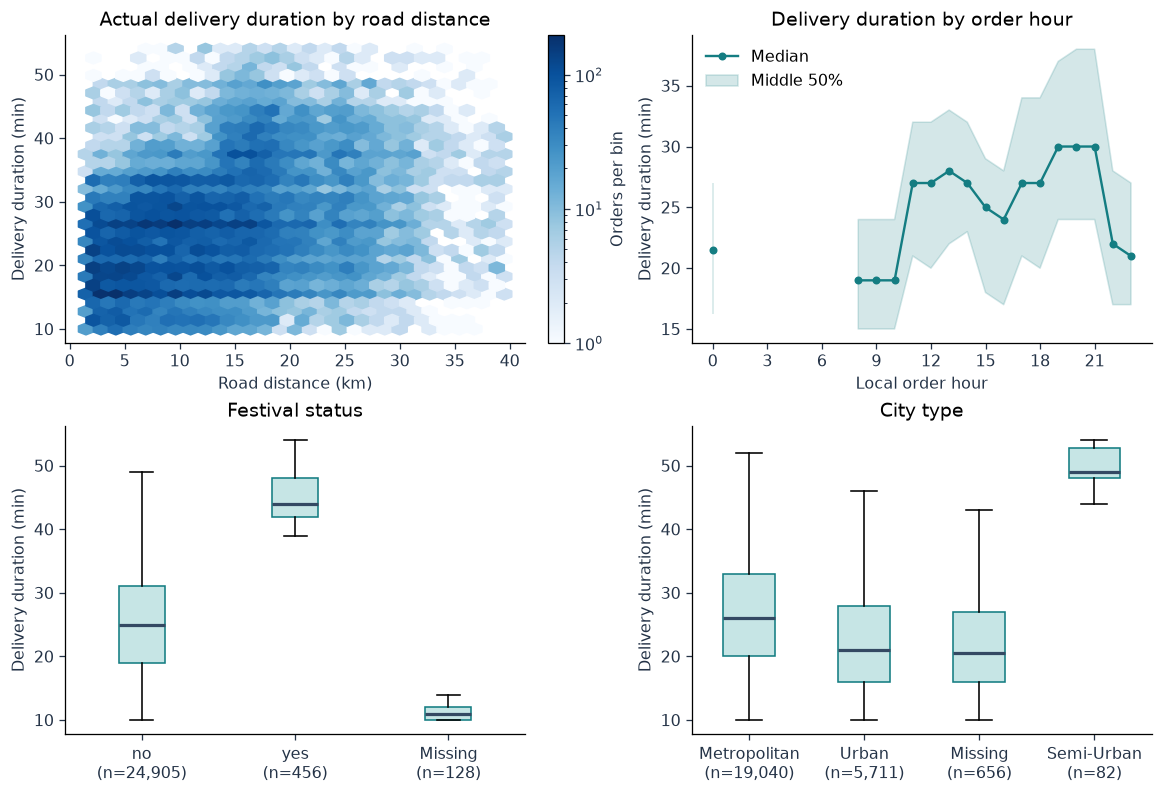

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.8), layout="constrained")
ax = axes[0, 0]
density = ax.hexbin(train["road_distance_km"], train[target], gridsize=28, bins="log",
                   mincnt=1, cmap="Blues")
fig.colorbar(density, ax=ax, label="Orders per bin")
ax.set(title="Actual delivery duration by road distance",
       xlabel="Road distance (km)", ylabel="Delivery duration (min)")

hour = train.groupby("order_hour")[target].agg(
    median="median", q1=lambda series: series.quantile(0.25), q3=lambda series: series.quantile(0.75)
).reindex(range(24)).astype(float)
ax = axes[0, 1]
ax.plot(hour.index, hour["median"], "o-", color=teal, markersize=4, label="Median")
ax.fill_between(hour.index, hour["q1"], hour["q3"], color=teal, alpha=0.18, label="Middle 50%")
ax.set(title="Delivery duration by order hour", xlabel="Local order hour", ylabel="Delivery duration (min)")
ax.set_xticks(range(0, 24, 3))
ax.legend(frameon=False)

for ax, column, title in zip(axes[1], ("Festival", "City"), ("Festival status", "City type")):
    labels = train[column].fillna("Missing")
    groups = labels.value_counts()
    ax.boxplot(
        [train.loc[labels.eq(label), target].to_numpy(dtype=float) for label in groups.index],
        showfliers=False, patch_artist=True,
        boxprops={"facecolor": "#c6e5e5", "edgecolor": teal},
        medianprops={"color": slate, "linewidth": 2},
    )
    ax.set_xticks(range(1, len(groups) + 1), [f"{name}\n(n={count:,})" for name, count in groups.items()])
    ax.set(title=title, ylabel="Delivery duration (min)")
plt.show()

## Select features using validation MAE

The probes use a fixed Decision Tree and a fixed histogram gradient boosting model. Each fits the same preprocessing used by the trainer. Compare the original six inputs, the four selected inputs, single-feature removals from the original set, and additions of estimated drive time. Both probes train on the oldest orders and score the middle partition. Smaller mean absolute error (MAE) is better.

I treated a validation MAE difference under 0.01 minute as too small to justify another input. The four-input set stays within this margin in both probes. Removing road distance, order hour, festival status, or city type individually increases error. Estimated drive time does not materially improve either probe, and straight-line distance strongly overlaps with the road distance already available in the app.

Validation MAE (min)                     \
                                          Decision Tree Histogram boosting   
Original six                                     6.3825             6.1694   
Selected four                                    6.3840             6.1708   
Road distance only                               7.3744             7.3730   
Selected four + drive time                       6.3844             6.1735   
Original six + drive time                        6.3824             6.1781   
Original without Type_of_order                   6.3829             6.1747   
Original without Festival                        6.5385             6.4592   
Original without City                            6.4376             6.3367   
Original without order_hour                      6.9071             6.7810   
Original without order_day_of_week               6.3844             6.1700   
Original without road_distance_km                6.4848             6.4464   

                                   Change vs. original six (min)  \
                                                   Decision Tree   
Original six                                              0.0000   
Selected four                                             0.0014   
Road distance only                                        0.9919   
Selected four + drive time                                0.0018   
Original six + drive time                                -0.0001   
Original without Type_of_order                            0.0004   
Original without Festival                                 0.1559   
Original without City                                     0.0550   
Original without order_hour                               0.5245   
Original without order_day_of_week                        0.0019   
Original without road_distance_km                         0.1023   

                                                       
                                   Histogram boosting  
Original six                                   0.0000  
Selected four                                  0.0014  
Road distance only                             1.2036  
Selected four + drive time                     0.0042  
Original six + drive time                      0.0087  
Original without Type_of_order                 0.0054  
Original without Festival                      0.2898  
Original without City                          0.1673  
Original without order_hour                    0.6116  
Original without order_day_of_week             0.0006  
Original without road_distance_km              0.2770

Validation MAE with known festival and city labels (5,285 orders)


,Decision Tree,Histogram boosting
Original six,6.3289,6.1834
Original without Festival,6.4875,6.4113
Original without City,6.3722,6.3379


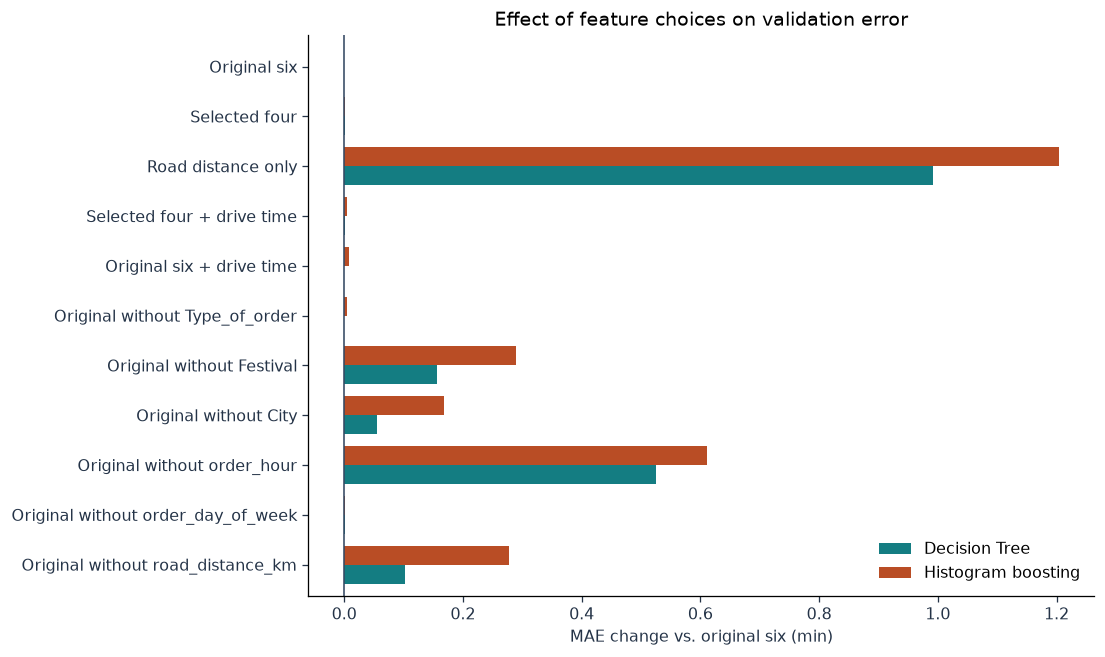

In [7]:
original = [("road_distance_km" if column == "distance_km" else column)
            for column in schema["feature_allowlist"]]
feature_sets = {
    "Original six": original,
    "Selected four": selected,
    "Road distance only": ["road_distance_km"],
    "Selected four + drive time": [*selected, "route_duration_minutes"],
    "Original six + drive time": [*original, "route_duration_minutes"],
    **{f"Original without {column}": [feature for feature in original if feature != column]
       for column in original},
}
probes = {
    "Decision Tree": DecisionTreeRegressor(max_depth=5, min_samples_leaf=80, random_state=42),
    "Histogram boosting": HistGradientBoostingRegressor(
        max_iter=150, max_leaf_nodes=15, l2_regularization=1, random_state=42
    ),
}
known_categories = validation[["Festival", "City"]].notna().all(axis=1)
category_checks = ("Original six", "Original without Festival", "Original without City")
scores, complete_scores = {}, {}
for label, columns in feature_sets.items():
    scores[label] = {}
    if label in category_checks:
        complete_scores[label] = {}
    for name, estimator in probes.items():
        pipeline = build_training_pipeline(columns, clone(estimator)).fit(train[columns], train[target])
        predictions = pipeline.predict(validation[columns])
        scores[label][name] = mean_absolute_error(validation[target], predictions)
        if label in category_checks:
            complete_scores[label][name] = mean_absolute_error(
                validation.loc[known_categories, target], predictions[known_categories]
            )

mae = pd.DataFrame.from_dict(scores, orient="index")
delta = mae - mae.loc["Original six"]
display(pd.concat({"Validation MAE (min)": mae, "Change vs. original six (min)": delta}, axis=1).round(4))
print(f"Validation MAE with known festival and city labels ({known_categories.sum():,} orders)")
display(pd.DataFrame.from_dict(complete_scores, orient="index").round(4))

fig, ax = plt.subplots(figsize=(9.5, 5.6), layout="constrained")
delta.iloc[::-1].plot.barh(ax=ax, color=[teal, rust], width=0.76)
ax.axvline(0, color=slate, linewidth=1)
ax.set(title="Effect of feature choices on validation error", xlabel="MAE change vs. original six (min)")
ax.legend(frameon=False, loc="lower right")
plt.show()

## Final inputs and reproducible data

| Input | Available at order placement |
| --- | --- |
| `Festival` | Whether the order is placed during a festival |
| `City` | The restaurant’s city type |
| `order_hour` | Local hour of the order |
| `road_distance_km` | OSRM road distance between the restaurant and the delivery address |

Pickup fields, identifiers, the target, and fields with unverified order-time availability stay outside the feature matrix. Numeric missing values use training medians. Categorical missing values use an `unknown` label before one-hot encoding. Unseen categories receive all zeros for their feature. The encoded export contains a split label, the order timestamp, the delivery target, and the transformed inputs.

From `apps/backend`, run `python -m ml.scripts.prepare` to regenerate the export. Select `split == "train"` when fitting a model from this snapshot. Use `numeric__` and `categorical__` columns as predictors. The trainer fits preprocessing inside each model pipeline on the raw routed features.

In [8]:
display(train[selected].isna().sum().rename("Training values imputed").to_frame())
prepared = pd.read_parquet(paths.prepared_parquet)
pd.testing.assert_frame_equal(prepared, prepare_partitions(split, selected, target))
encoded = prepared.filter(regex=r"^(numeric|categorical)__")
assert np.isfinite(encoded.to_numpy()).all()
display(pd.DataFrame({
    "Orders": prepared["split"].value_counts(sort=False),
    "Encoded predictors": encoded.shape[1],
}))
print(f"Verified {len(prepared):,} prepared orders in {paths.prepared_parquet.name}.")

,Training values imputed
Festival,128
City,656
order_hour,0
road_distance_km,0


,Orders,Encoded predictors
split,,
train,25489,9
validation,5464,9
test,5463,9


Verified 36,416 prepared orders in dataset_prepared.parquet.
